Generated 19 steps.
Simulation Complete. Framework is decoupled.
SiL Simulation Complete. Calculating Metrics and Rendering...


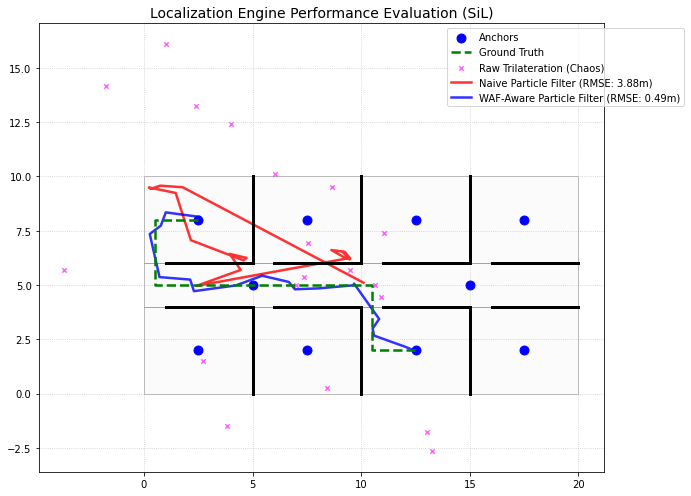

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 导入配置模块 (定义物理常数)
from config import SpatialConfig, RFConfig, KinematicsConfig

# 2. 导入环境模块 (构建地图拓扑)
from environment import MapBuilder

# 3. 导入仿真模块 (生成 GT 轨迹与带噪测量值)
from simulator import TrajectoryGenerator, SensorModel

# 4. 导入解算器模块 (不同的算法 Backbone)
from solvers import RawSolver, ParticleFilterSolver

# 5. 导入评估模块 (计算指标与可视化)
from evaluator import PerformanceEvaluator


# main.py
def main():
    np.random.seed(1024)
    
    # 1. Load Configs
    spatial_cfg = SpatialConfig()
    rf_cfg = RFConfig()
    kin_cfg = KinematicsConfig()

    # 2. Build Environment
    builder = MapBuilder(spatial_cfg)
    rooms, walls, anchors = builder.build()

    # 3. Init Simulator
    traj_gen = TrajectoryGenerator(kin_cfg)
    sensor = SensorModel(rf_cfg, walls, anchors)

    # Generate GT Path
    waypoints = [[2.5, 8.0], [0.5, 8.0], [0.5, 5.0], [10.5, 5.0], [10.5, 2.0], [12.5, 2.0]]
    gt_path = traj_gen.generate(waypoints)

    # 4. Init Solvers
    raw_solver = RawSolver(anchors, rf_cfg)
    pf_naive = ParticleFilterSolver(1000, rooms, walls, anchors, rf_cfg, use_waf=False)
    pf_waf = ParticleFilterSolver(1000, rooms, walls, anchors, rf_cfg, use_waf=True)

    # 5. Simulation Loop
    res_raw, res_naive, res_waf = [], [], []
    for pos in gt_path:
        measurements = sensor.get_measurements(pos)
        
        res_raw.append(raw_solver.step(measurements))
        res_naive.append(pf_naive.step(measurements))
        res_waf.append(pf_waf.step(measurements))

    # Output to verify
    print(f"Generated {len(gt_path)} steps.")
    print("Simulation Complete. Framework is decoupled.")

    # 将结果打包为字典
    solver_results = {
        "Raw Trilateration": np.array(res_raw),
        "Naive Particle Filter": np.array(res_naive),
        "WAF-Aware Particle Filter": np.array(res_waf)
    }

    # 6. 后处理：实例化评估器并渲染
    evaluator = PerformanceEvaluator(rooms, walls, anchors)
    
    print("SiL Simulation Complete. Calculating Metrics and Rendering...")
    evaluator.render(true_path=gt_path, results=solver_results)


if __name__ == "__main__":
    main()